In [17]:
import numpy as np
import pandas as pd

from scipy import stats
from scipy.stats import binomtest

import statsmodels.api as sm

import matplotlib.pyplot as plt

In [4]:

market = pd.read_csv(
    "data/processed/market_daily.csv", parse_dates=["date"]
).sort_values("date")

elections = pd.read_csv(
    "data/processed/election_events.csv",
    parse_dates=["election_date"]
)

spx = (
    market[["date", "spx_close"]]
    .dropna()
    .sort_values("date")
    .drop_duplicates("date")
    .reset_index(drop=True)
)
spx["ret"] = np.log(spx["spx_close"] / spx["spx_close"].shift(1))
spx = spx.dropna().reset_index(drop=True)

event_rows = []

for _, e in elections.iterrows():
    d = e["election_date"]
    before = spx.loc[spx["date"] < d]
    after = spx.loc[spx["date"] > d]

    if len(before) < 20 or len(after) < 60:
        continue

    row = {"year": int(e["election_year"]), "date": d}

    for label, r in [
        ("pre20", before["ret"].tail(20)),
        ("post5", after["ret"].head(5)),
        ("post20", after["ret"].head(20)),
        ("post60", after["ret"].head(60)),
    ]:
        row[f"{label}_return"] = np.expm1(r.sum()) * 100
        row[f"{label}_rv"] = np.sqrt((r ** 2).sum()) * 100

    # Election-day return only if Election Day was a market session.
    same_day = spx.loc[spx["date"] == d, "ret"]
    row["election_day_return"] = (
        np.expm1(same_day.iloc[0]) * 100 if len(same_day) else np.nan
    )
    event_rows.append(row)

events = pd.DataFrame(event_rows).sort_values("year").reset_index(drop=True)
display(events.round(3))
print("Usable election events:", len(events))


C:\Users\JM2090\AppData\Local\Temp\ipykernel_14796\155853816.py:49: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(events.round(3))


,year,date,pre20_return,pre20_rv,post5_return,post5_rv,post20_return,post20_rv,post60_return,post60_rv,election_day_return
0,1962,1962-11-06,2.243,5.763,1.902,1.833,6.924,3.306,13.642,4.732,NaN
1,1966,1966-11-08,8.319,3.950,1.189,1.296,1.226,2.980,8.213,4.598,NaN
2,1970,1970-11-03,-3.423,2.686,0.677,0.695,5.058,3.115,13.845,4.360,0.850
3,1974,1974-11-05,12.517,8.926,-1.917,2.197,-10.252,6.018,2.490,10.229,2.778
4,1978,1978-11-07,-8.987,6.155,-1.449,2.017,3.879,3.948,6.020,6.154,-1.408
5,1982,1982-11-02,11.490,7.789,4.022,4.475,0.756,8.333,3.091,11.028,1.499
6,1986,1986-11-04,4.694,3.032,0.357,0.528,3.107,4.552,11.324,7.339,0.163
7,1990,1990-11-06,0.354,6.211,1.941,3.328,5.873,4.600,10.086,7.654,-0.944
8,1994,1994-11-08,0.876,3.206,-0.133,0.960,-3.097,2.814,3.337,4.217,0.559
9,1998,1998-11-03,12.446,6.197,1.568,1.903,5.438,4.358,14.601,9.163,-0.068


Usable election events: 16


In [6]:
test_rows = []

for window in ["pre20", "post5", "post20", "post60"]:
    x = events[f"{window}_return"].dropna().to_numpy()
    n = len(x)
    mean = x.mean()
    se = stats.sem(x)
    ci = stats.t.interval(0.95, n - 1, loc=mean, scale=se)

    sign_p = binomtest(
        int((x > 0).sum()), n, p=0.5, alternative="two-sided"
    ).pvalue

    test_rows.append({
        "window": window,
        "n": n,
        "mean_return_pct": mean,
        "median_return_pct": np.median(x),
        "mean_ci_low": ci[0],
        "mean_ci_high": ci[1],
        "t_test_p": stats.ttest_1samp(x, 0).pvalue,
        "positive_fraction": (x > 0).mean(),
        "sign_test_p": sign_p,
    })

tests_zero = pd.DataFrame(test_rows)
display(tests_zero.round(4))


,window,n,mean_return_pct,median_return_pct,mean_ci_low,mean_ci_high,t_test_p,positive_fraction,sign_test_p
0,pre20,16,4.0958,3.4306,0.4704,7.7212,0.0294,0.8125,0.0213
1,post5,16,0.7164,0.9699,-0.3765,1.8094,0.1827,0.6875,0.2101
2,post20,16,1.6290,2.4692,-0.6079,3.8659,0.1414,0.8125,0.0213
3,post60,16,6.2163,6.4775,3.1553,9.2772,0.0006,0.8750,0.0042


In [8]:

def first_tuesday_after_first_monday(year):
    nov1 = pd.Timestamp(year=year, month=11, day=1)
    first_monday = nov1 + pd.Timedelta(days=(7 - nov1.weekday()) % 7)
    return first_monday + pd.Timedelta(days=1)

midterm_years = set(elections["election_year"].astype(int))
control_rows = []

for year in range(spx["date"].min().year, spx["date"].max().year + 1):
    if year in midterm_years:
        continue

    anchor = first_tuesday_after_first_monday(year)
    before = spx.loc[spx["date"] < anchor]
    after = spx.loc[spx["date"] > anchor]

    if len(before) < 20 or len(after) < 60:
        continue

    row = {
        "year": year,
        "period_type": "presidential" if year % 4 == 0 else "non-midterm",
    }

    for label, r in [
        ("pre20", before["ret"].tail(20)),
        ("post5", after["ret"].head(5)),
        ("post20", after["ret"].head(20)),
        ("post60", after["ret"].head(60)),
    ]:
        row[f"{label}_return"] = np.expm1(r.sum()) * 100
        row[f"{label}_rv"] = np.sqrt((r ** 2).sum()) * 100

    control_rows.append(row)

controls = pd.DataFrame(control_rows)

comparison_rows = []

for window in ["pre20", "post5", "post20", "post60"]:
    mid = events[f"{window}_return"].dropna().to_numpy()
    ctrl = controls[f"{window}_return"].dropna().to_numpy()

    comparison_rows.append({
        "window": window,
        "midterm_mean_pct": mid.mean(),
        "control_mean_pct": ctrl.mean(),
        "difference_pp": mid.mean() - ctrl.mean(),
        "control_n": len(ctrl),
        "control_mean_presidential": controls.loc[
            controls["period_type"] == "presidential",
            f"{window}_return"
        ].mean(),
        "control_mean_non_midterm": controls.loc[
            controls["period_type"] == "non-midterm",
            f"{window}_return"
        ].mean(),
    })

comparison = pd.DataFrame(comparison_rows)
display(comparison.round(3))

,window,midterm_mean_pct,control_mean_pct,difference_pp,control_n,control_mean_presidential,control_mean_non_midterm
0,pre20,4.096,-0.003,4.099,51,-0.223,0.107
1,post5,0.716,0.224,0.492,51,-0.335,0.504
2,post20,1.629,1.000,0.629,51,1.230,0.885
3,post60,6.216,2.363,3.853,51,3.058,2.016


,window,mean_rv_pct,median_rv_pct,positive_return_fraction
0,pre20,5.462,5.959,0.812
1,post20,4.541,4.455,0.812


Full-sample post-60 mean (%): 6.216
Leave-one-out mean range (%): 5.657 to 7.032


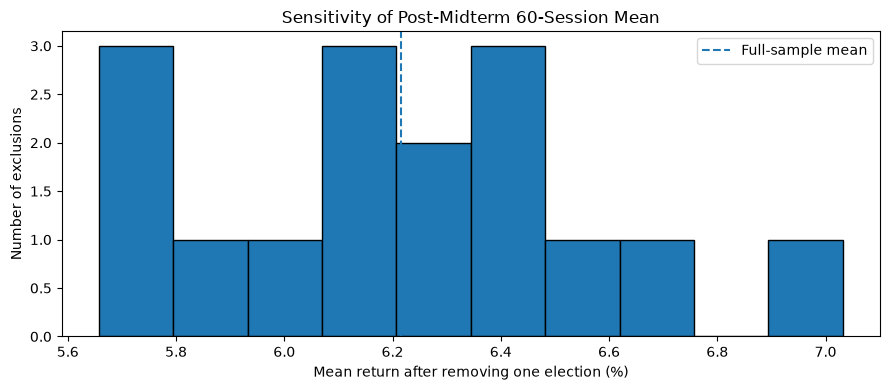

In [9]:
# Volatility comparison: equal-length windows only.
rv_rows = []

for window in ["pre20", "post20"]:
    x = events[f"{window}_rv"].dropna()
    rv_rows.append({
        "window": window,
        "mean_rv_pct": x.mean(),
        "median_rv_pct": x.median(),
        "positive_return_fraction": (
            events[f"{window}_return"] > 0
        ).mean(),
    })

display(pd.DataFrame(rv_rows).round(3))

# Leave-one-election-out sensitivity for post-election returns.
x = events["post60_return"].dropna().to_numpy()
loo_means = np.array([np.delete(x, i).mean() for i in range(len(x))])

print("Full-sample post-60 mean (%):", round(x.mean(), 3))
print("Leave-one-out mean range (%):",
      round(loo_means.min(), 3), "to", round(loo_means.max(), 3))

plt.figure(figsize=(9, 4))
plt.hist(loo_means, bins=10, edgecolor="black")
plt.axvline(x.mean(), linestyle="--", label="Full-sample mean")
plt.title("Sensitivity of Post-Midterm 60-Session Mean")
plt.xlabel("Mean return after removing one election (%)")
plt.ylabel("Number of exclusions")
plt.legend()
plt.tight_layout()
plt.show()


In [12]:
# Source: American Presidency Project, seats gained/lost
# by the president's party in midterm elections.
seat_changes = {
    1962: (-4,  3), 1966: (-47, -4),
    1970: (-12, 2), 1974: (-48, -5),
    1978: (-15, -3), 1982: (-26, 1),
    1986: (-5, -8), 1990: (-8, -1),
    1994: (-54, -8), 1998: (4, 0),
    2002: (8, 2), 2006: (-30, -6),
    2010: (-63, -6), 2014: (-13, -9),
    2018: (-41, 2), 2022: (-9, 1),
}

politics = pd.DataFrame([
    {"year": year, "pres_party_house_seat_change": house,
     "pres_party_senate_seat_change": senate}
    for year, (house, senate) in seat_changes.items()
])

events = events.merge(politics, on="year", how="left", validate="one_to_one")

events["house_gain"] = events["pres_party_house_seat_change"] > 0
events["senate_gain"] = events["pres_party_senate_seat_change"] > 0
events["house_seat_change_abs"] = events["pres_party_house_seat_change"].abs()

display(events[["year", "pres_party_house_seat_change","pres_party_senate_seat_change",
    "post20_return", "post60_return"]].round(3))

,year,pres_party_house_seat_change,pres_party_senate_seat_change,post20_return,post60_return
0,1962,-4,3,6.924,13.642
1,1966,-47,-4,1.226,8.213
2,1970,-12,2,5.058,13.845
3,1974,-48,-5,-10.252,2.490
4,1978,-15,-3,3.879,6.020
5,1982,-26,1,0.756,3.091
6,1986,-5,-8,3.107,11.324
7,1990,-8,-1,5.873,10.086
8,1994,-54,-8,-3.097,3.337
9,1998,4,0,5.438,14.601


In [13]:
house_summary = (
    events.assign(
        house_result=np.where(events["house_gain"], "Gained", "Did not gain")
    )
    .groupby("house_result")
    .agg(
        elections=("year", "count"),
        mean_post20=("post20_return", "mean"),
        median_post20=("post20_return", "median"),
        mean_post60=("post60_return", "mean"),
        median_post60=("post60_return", "median"),
    )
)

display(house_summary.round(3))

gains = events.loc[events["house_gain"], "post60_return"].dropna()
no_gains = events.loc[~events["house_gain"], "post60_return"].dropna()

if len(gains) > 0 and len(no_gains) > 0:
    print("Welch test, post-60 returns by House gain status:",
          stats.ttest_ind(gains, no_gains, equal_var=False).pvalue)

print("Spearman correlation: House seat change vs post-60 return:",
      stats.spearmanr(
          events["pres_party_house_seat_change"],
          events["post60_return"]
      ))


,elections,mean_post20,median_post20,mean_post60,median_post60
house_result,,,,,
Did not gain,14,1.457,2.469,6.491,6.477
Gained,2,2.835,2.835,4.292,4.292


Welch test, post-60 returns by House gain status: 0.8663510058481536
Spearman correlation: House seat change vs post-60 return: SignificanceResult(statistic=np.float64(0.36470588235294116), pvalue=np.float64(0.16486839724475397))


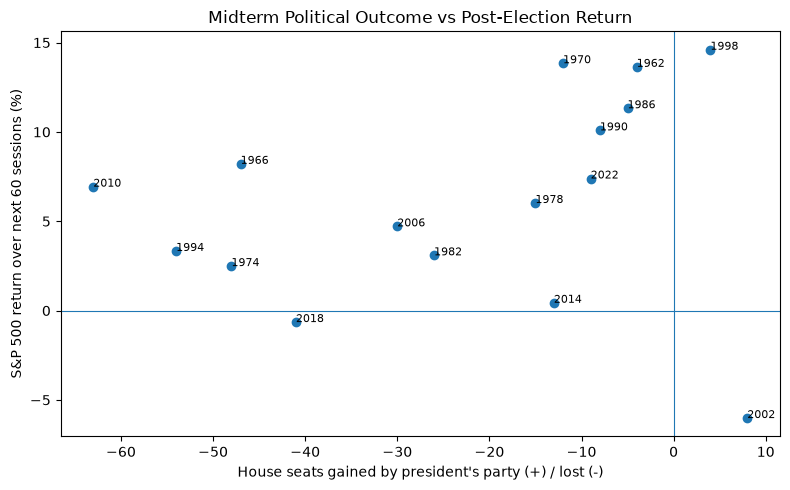

In [14]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    events["pres_party_house_seat_change"],
    events["post60_return"]
)

for _, row in events.iterrows():
    ax.annotate(
        str(row["year"]),
        (row["pres_party_house_seat_change"], row["post60_return"]),
        fontsize=8
    )

ax.axhline(0, linewidth=0.8)
ax.axvline(0, linewidth=0.8)
ax.set_xlabel("House seats gained by president's party (+) / lost (-)")
ax.set_ylabel("S&P 500 return over next 60 sessions (%)")
ax.set_title("Midterm Political Outcome vs Post-Election Return")
plt.tight_layout()
plt.show()


In [15]:
pre_rv = events["pre20_rv"].dropna()
post_rv = events.loc[pre_rv.index, "post20_rv"].dropna()

paired = pd.concat(
    [pre_rv.rename("pre"), post_rv.rename("post")], axis=1
).dropna()

print("Mean pre-election RV:", round(paired["pre"].mean(), 3))
print("Mean post-election RV:", round(paired["post"].mean(), 3))
print("Mean change (post - pre):",
      round((paired["post"] - paired["pre"]).mean(), 3))
print("Paired t-test p-value:",
      round(stats.ttest_rel(paired["post"], paired["pre"]).pvalue, 4))
print("Wilcoxon p-value:",
      round(stats.wilcoxon(paired["post"], paired["pre"]).pvalue, 4))

Mean pre-election RV: 5.462
Mean post-election RV: 4.541
Mean change (post - pre): -0.922
Paired t-test p-value: 0.0357
Wilcoxon p-value: 0.0507


In [18]:
reg = events[
    ["post60_return", "pre20_return", "pres_party_house_seat_change"]
].dropna()

X = sm.add_constant(
    reg[["pre20_return", "pres_party_house_seat_change"]]
)
y = reg["post60_return"]

model = sm.OLS(y, X).fit(cov_type="HC3")
print(model.summary())


                            OLS Regression Results                            
Dep. Variable:          post60_return   R-squared:                       0.100
Model:                            OLS   Adj. R-squared:                 -0.038
Method:                 Least Squares   F-statistic:                     1.271
Date:                Wed, 28 Oct 2026   Prob (F-statistic):              0.313
Time:                        13:51:08   Log-Likelihood:                -49.315
No. Observations:                  16   AIC:                             104.6
Df Residuals:                      13   BIC:                             106.9
Df Model:                           2                                         
Covariance Type:                  HC3                                         
                                   coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------
const           

In [19]:
windows = ["pre20", "post5", "post20", "post60"]
rng = np.random.default_rng(42)
B = 10_000
results = []

for w in windows:
    mid = events[f"{w}_return"].dropna().to_numpy()
    ctrl = controls[f"{w}_return"].dropna().to_numpy()

    if len(mid) < 2 or len(ctrl) < 2:
        print(f"Skipping {w}: insufficient observations")
        continue

    diff = mid.mean() - ctrl.mean()

    # Welch test: unequal variances and sample sizes allowed
    test = stats.ttest_ind(mid, ctrl, equal_var=False)

    # Welch confidence interval for the difference in means
    se = np.sqrt(mid.var(ddof=1) / len(mid) + ctrl.var(ddof=1) / len(ctrl))
    df_num = (mid.var(ddof=1) / len(mid) + ctrl.var(ddof=1) / len(ctrl)) ** 2
    df_den = (
        (mid.var(ddof=1) / len(mid)) ** 2 / (len(mid) - 1)
        + (ctrl.var(ddof=1) / len(ctrl)) ** 2 / (len(ctrl) - 1)
    )
    df = df_num / df_den
    critical = stats.t.ppf(0.975, df)
    ci_low, ci_high = diff - critical * se, diff + critical * se

    # Bootstrap CI for difference in means
    boot_mid = rng.choice(mid, size=(B, len(mid)), replace=True).mean(axis=1)
    boot_ctrl = rng.choice(ctrl, size=(B, len(ctrl)), replace=True).mean(axis=1)
    boot_diff = boot_mid - boot_ctrl
    boot_low, boot_high = np.percentile(boot_diff, [2.5, 97.5])

    results.append({
        "window": w,
        "midterm_n": len(mid),
        "control_n": len(ctrl),
        "midterm_mean_pct": mid.mean() * 100,
        "control_mean_pct": ctrl.mean() * 100,
        "difference_pp": diff * 100,
        "welch_ci_low_pp": ci_low * 100,
        "welch_ci_high_pp": ci_high * 100,
        "bootstrap_ci_low_pp": boot_low * 100,
        "bootstrap_ci_high_pp": boot_high * 100,
        "welch_p": test.pvalue,
    })

comparison = pd.DataFrame(results).round(4)
display(comparison)

print("\nINTERPRETATION")
for _, r in comparison.iterrows():
    direction = "higher" if r["difference_pp"] > 0 else "lower"
    print(
        f'{r["window"]}: midterm mean was {abs(r["difference_pp"]):.2f} '
        f'percentage points {direction} than controls; '
        f'Welch p={r["welch_p"]:.4f}.'
    )

print("\nCaution: only 16 midterm events; multiple windows are tested. "
    "Treat results as exploratory, not causal or guaranteed predictive evidence.")

,window,midterm_n,control_n,midterm_mean_pct,control_mean_pct,difference_pp,welch_ci_low_pp,welch_ci_high_pp,bootstrap_ci_low_pp,bootstrap_ci_high_pp,welch_p
0,pre20,16,51,409.5801,-0.3222,409.9024,26.8952,792.9095,63.8695,767.9608,0.0372
1,post5,16,51,71.6445,22.4458,49.1986,-79.9108,178.3081,-70.3604,170.2245,0.4435
2,post20,16,51,162.9034,99.9887,62.9146,-186.9853,312.8146,-180.3767,279.0144,0.6092
3,post60,16,51,621.6279,236.3244,385.3034,34.2615,736.3454,53.4473,711.7616,0.0326



INTERPRETATION
pre20: midterm mean was 409.90 percentage points higher than controls; Welch p=0.0372.
post5: midterm mean was 49.20 percentage points higher than controls; Welch p=0.4435.
post20: midterm mean was 62.91 percentage points higher than controls; Welch p=0.6092.
post60: midterm mean was 385.30 percentage points higher than controls; Welch p=0.0326.

Caution: only 16 midterm events; multiple windows are tested. Treat results as exploratory, not causal or guaranteed predictive evidence.


In [20]:
# FINAL NOTEBOOK SUMMARY
print("MIDTERM HYPOTHESIS TESTING — SUMMARY")
print(f"Midterm events analysed: {len(events)}")

print("\nReturn tests against zero:")
display(tests_zero.round(4))

print("\nMidterm vs control November windows:")
display(comparison)

print("\nVolatility comparison:")
print(f"Pre-election 20-session RV mean:  {events['pre20_rv'].mean():.3f}%")
print(f"Post-election 20-session RV mean: {events['post20_rv'].mean():.3f}%")
print(
    f"Mean change: "
    f"{(events['post20_rv'] - events['pre20_rv']).mean():.3f} percentage points"
)

print("\nRegression:")
print(f"R-squared: {model.rsquared:.3f}")
print(f"Overall model p-value: {model.f_pvalue:.4f}")
print("Neither predictor was statistically significant at the 5% level.")

print(
    "\nConclusion: historical midterm windows show potentially interesting "
    "return and volatility patterns, but the sample is small and these tests "
    "do not establish that elections cause the patterns or reliably forecast "
    "future returns. Political seat-change results require source verification."
)

MIDTERM HYPOTHESIS TESTING — SUMMARY
Midterm events analysed: 16

Return tests against zero:


,window,n,mean_return_pct,median_return_pct,mean_ci_low,mean_ci_high,t_test_p,positive_fraction,sign_test_p
0,pre20,16,4.0958,3.4306,0.4704,7.7212,0.0294,0.8125,0.0213
1,post5,16,0.7164,0.9699,-0.3765,1.8094,0.1827,0.6875,0.2101
2,post20,16,1.6290,2.4692,-0.6079,3.8659,0.1414,0.8125,0.0213
3,post60,16,6.2163,6.4775,3.1553,9.2772,0.0006,0.8750,0.0042



Midterm vs control November windows:


,window,midterm_n,control_n,midterm_mean_pct,control_mean_pct,difference_pp,welch_ci_low_pp,welch_ci_high_pp,bootstrap_ci_low_pp,bootstrap_ci_high_pp,welch_p
0,pre20,16,51,409.5801,-0.3222,409.9024,26.8952,792.9095,63.8695,767.9608,0.0372
1,post5,16,51,71.6445,22.4458,49.1986,-79.9108,178.3081,-70.3604,170.2245,0.4435
2,post20,16,51,162.9034,99.9887,62.9146,-186.9853,312.8146,-180.3767,279.0144,0.6092
3,post60,16,51,621.6279,236.3244,385.3034,34.2615,736.3454,53.4473,711.7616,0.0326



Volatility comparison:
Pre-election 20-session RV mean:  5.462%
Post-election 20-session RV mean: 4.541%
Mean change: -0.922 percentage points

Regression:
R-squared: 0.100
Overall model p-value: 0.3132
Neither predictor was statistically significant at the 5% level.

Conclusion: historical midterm windows show potentially interesting return and volatility patterns, but the sample is small and these tests do not establish that elections cause the patterns or reliably forecast future returns. Political seat-change results require source verification.


In [21]:

windows = ["pre20", "post5", "post20", "post60"]
rng = np.random.default_rng(42)
B = 10_000
results = []

for w in windows:
    mid = events[f"{w}_return"].dropna().to_numpy()
    ctrl = controls[f"{w}_return"].dropna().to_numpy()

    # Both series are already expressed in percentage units
    diff = mid.mean() - ctrl.mean()
    test = stats.ttest_ind(mid, ctrl, equal_var=False)

    # Welch confidence interval
    v1, v2 = mid.var(ddof=1), ctrl.var(ddof=1)
    se1, se2 = v1 / len(mid), v2 / len(ctrl)
    se = np.sqrt(se1 + se2)

    df = (se1 + se2)**2 / (
        se1**2 / (len(mid) - 1) + se2**2 / (len(ctrl) - 1)
    )
    crit = stats.t.ppf(0.975, df)
    ci_low, ci_high = diff - crit * se, diff + crit * se

    # Bootstrap confidence interval
    boot_mid = rng.choice(mid, (B, len(mid)), replace=True).mean(axis=1)
    boot_ctrl = rng.choice(ctrl, (B, len(ctrl)), replace=True).mean(axis=1)
    boot_diff = boot_mid - boot_ctrl
    boot_low, boot_high = np.percentile(boot_diff, [2.5, 97.5])

    results.append({
        "window": w,
        "midterm_n": len(mid),
        "control_n": len(ctrl),
        "midterm_mean_pct": mid.mean(),
        "control_mean_pct": ctrl.mean(),
        "difference_pp": diff,
        "welch_ci_low_pp": ci_low,
        "welch_ci_high_pp": ci_high,
        "bootstrap_ci_low_pp": boot_low,
        "bootstrap_ci_high_pp": boot_high,
        "welch_p": test.pvalue
    })

comparison = pd.DataFrame(results).round(4)
display(comparison)

,window,midterm_n,control_n,midterm_mean_pct,control_mean_pct,difference_pp,welch_ci_low_pp,welch_ci_high_pp,bootstrap_ci_low_pp,bootstrap_ci_high_pp,welch_p
0,pre20,16,51,4.0958,-0.0032,4.0990,0.2690,7.9291,0.6387,7.6796,0.0372
1,post5,16,51,0.7164,0.2245,0.4920,-0.7991,1.7831,-0.7036,1.7022,0.4435
2,post20,16,51,1.6290,0.9999,0.6291,-1.8699,3.1281,-1.8038,2.7901,0.6092
3,post60,16,51,6.2163,2.3632,3.8530,0.3426,7.3635,0.5345,7.1176,0.0326


Research questions tested

1. Are returns unusual in the 20 sessions before midterms?
2. Are returns different from zero over the first 5, 20, and 60 sessions after midterms?
3. Do these returns differ from non-midterm November periods?
4. Does realized volatility change after midterms?
5. Do pre-election returns or House seat changes explain subsequent returns?
   
Main results

Test	Result	Interpretation

Pre-election 20-session return	Mean 4.10%, p=0.0294 vs zero	Positive historical average
Post-election 5-session return	Mean 0.72%, p=0.1827 vs zero	Not statistically significant
Post-election 20-session return	Mean 1.63%, p=0.1414 vs zero	Mean not significant by t-test
Post-election 60-session return	Mean 6.22%, p=0.0006 vs zero	Positive historical average
Pre-election vs control, 20 sessions	Difference +4.10 percentage points, p=0.0372	Higher than the non-midterm November baseline
Post-election vs control, 5 sessions	Difference +0.49 pp, \(p=0.4435\)	No convincing difference
Post-election vs control, 20 sessions	Difference +0.63 pp, \(p=0.6092\)	No convincing difference
Post-election vs control, 60 sessions	Difference +3.85 pp, \(p=0.0326\)	Higher than the control baseline
20-session realized volatility	Fell from 5.462% to 4.541%; paired t-test \(p=0.0357\)	Possible post-election volatility decline
Political/return regression	\(R^2=0.10\), overall \(p=0.3132\)	Weak explanatory evidence

The Wilcoxon test for volatility had \(p=0.0507\), just above the conventional 5% threshold. That makes the volatility result suggestive rather than definitive.
What these results do—and do not—establish
The historical data show a positive average 60-session return after midterms and a higher average than the non-midterm November baseline. However, only 16 midterm events are available. Results can be sensitive to a few exceptional periods, market regimes, and how the comparison windows are selected. Multiple testing also increases the chance of finding apparently significant results.

The regression does not establish that political seat changes have no effect; it shows that this small sample does not estimate such a relationship precisely. We must also verify political seat-change data before relying on it in a research paper.

Conclusion: The notebook provides useful preliminary evidence of historical return patterns. It does not yet establish a robust forecasting rule, a causal election effect, or an actionable trading signal. The next notebook will focus on conditional probabilities and will compare the available indices and ETFs rather than relying only on the S&P 500.